In [1]:
print("Vision Reliability Lab")
print("Research experiment: Initial setup")
print("Status: Ready to begin")

Vision Reliability Lab
Research experiment: Initial setup
Status: Ready to begin


In [2]:
!pip -q install transformers torch pillow

In [3]:
import transformers
import torch
import PIL

print("Transformers:", transformers.__version__)
print("PyTorch:", torch.__version__)
print("Pillow:", PIL.__version__)

Transformers: 5.22.1
PyTorch: 2.14.1+cpu
Pillow: 11.3.0


In [4]:
from transformers import CLIPModel, CLIPProcessor

model_name = "openai/clip-vit-base-patch32"

processor = CLIPProcessor.from_pretrained(model_name)
model = CLIPModel.from_pretrained(model_name)

model.eval()

print("CLIP model loaded successfully!")

preprocessor_config.json:   0%|          | 0.00/316 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/4.19k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/592 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/862k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.22M [00:00<?, ?B/s]

... (3 outputs left out)

model.safetensors: reconstructing file:   0%|          |  0.00B /  605MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

CLIP model loaded successfully!


In [5]:
from PIL import Image
import requests
import torch

image_url = "https://images.unsplash.com/photo-1514888286974-6c03e2ca1dba?w=500"
image = Image.open(requests.get(image_url, stream=True).raw).convert("RGB")

labels = [
    "a photo of a cat",
    "a photo of a dog",
    "a photo of a bird",
    "a photo of a car"
]

inputs = processor(
    text=labels,
    images=image,
    return_tensors="pt",
    padding=True
)

with torch.no_grad():
    outputs = model(**inputs)
    scores = outputs.logits_per_image.softmax(dim=1)[0]

for label, score in zip(labels, scores):
    print(f"{label}: {score.item():.4f}")

a photo of a cat: 0.9939
a photo of a dog: 0.0055
a photo of a bird: 0.0006
a photo of a car: 0.0001


In [6]:
from google.colab import files

uploaded = files.upload()

Saving image4.jpeg to image4.jpeg


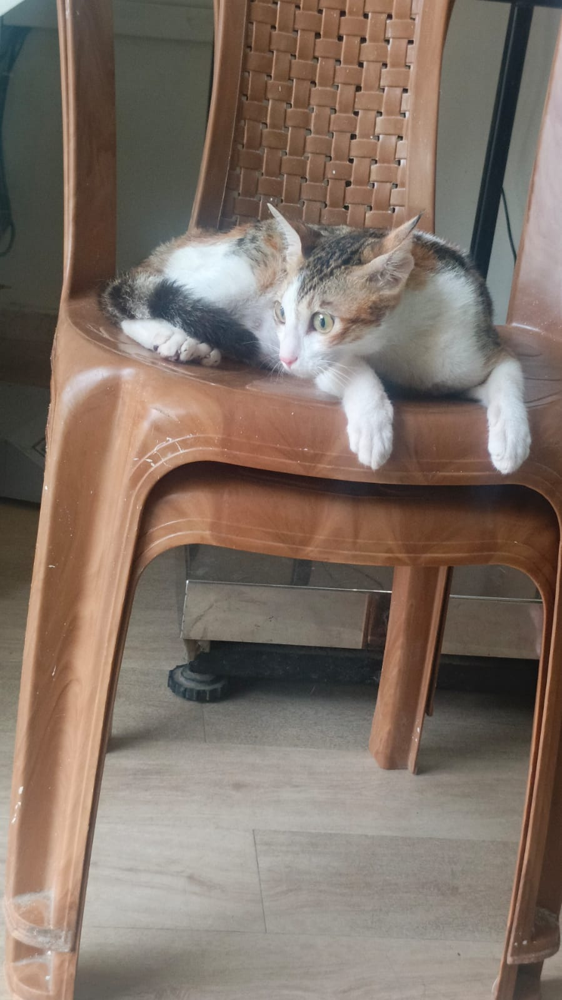

In [7]:
from PIL import Image
from IPython.display import display

image_path = next(iter(uploaded.keys()))
image = Image.open(image_path).convert("RGB")

display(image)

In [8]:
labels = [
    "a photo of a cat",
    "a photo of a dog",
    "a photo of a rabbit",
    "a photo of a bird",
    "a photo of a person"
]

inputs = processor(
    text=labels,
    images=image,
    return_tensors="pt",
    padding=True
)

with torch.no_grad():
    outputs = model(**inputs)
    scores = outputs.logits_per_image.softmax(dim=1)[0]

for label, score in zip(labels, scores):
    print(f"{label}: {score.item():.4f}")

a photo of a cat: 0.9825
a photo of a dog: 0.0072
a photo of a rabbit: 0.0033
a photo of a bird: 0.0016
a photo of a person: 0.0055


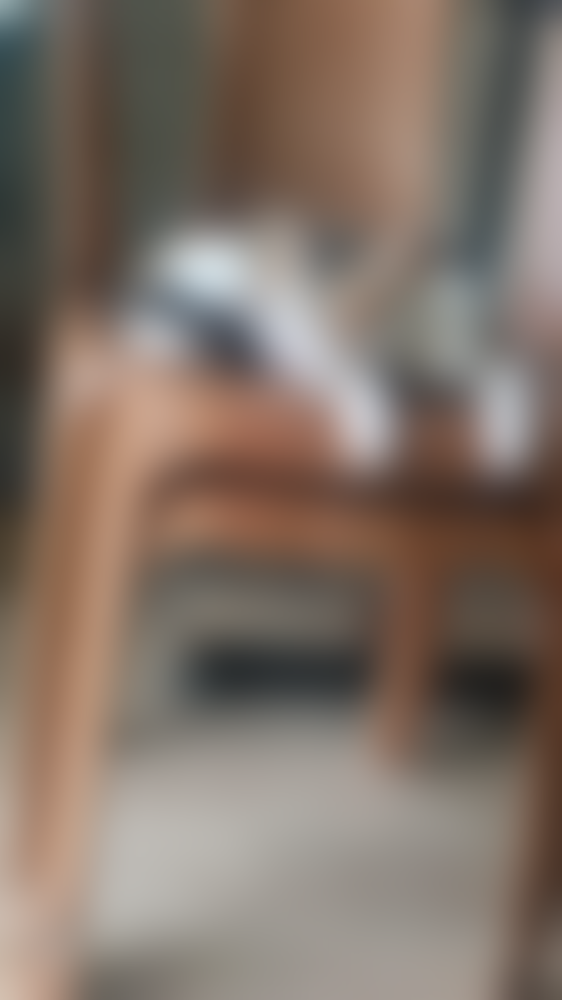

In [9]:
from PIL import ImageFilter
from IPython.display import display

blurred_image = image.filter(ImageFilter.GaussianBlur(radius=30))

display(blurred_image)

In [10]:
inputs = processor(
    text=labels,
    images=blurred_image,
    return_tensors="pt",
    padding=True
)

with torch.no_grad():
    outputs = model(**inputs)
    scores = outputs.logits_per_image.softmax(dim=1)[0]

for label, score in zip(labels, scores):
    print(f"{label}: {score.item():.4f}")

a photo of a cat: 0.1513
a photo of a dog: 0.1986
a photo of a rabbit: 0.1348
a photo of a bird: 0.1222
a photo of a person: 0.3931


In [11]:

from google.colab import files

uploaded = files.upload()


Saving vision-images.zip to vision-images.zip


Total images found: 30


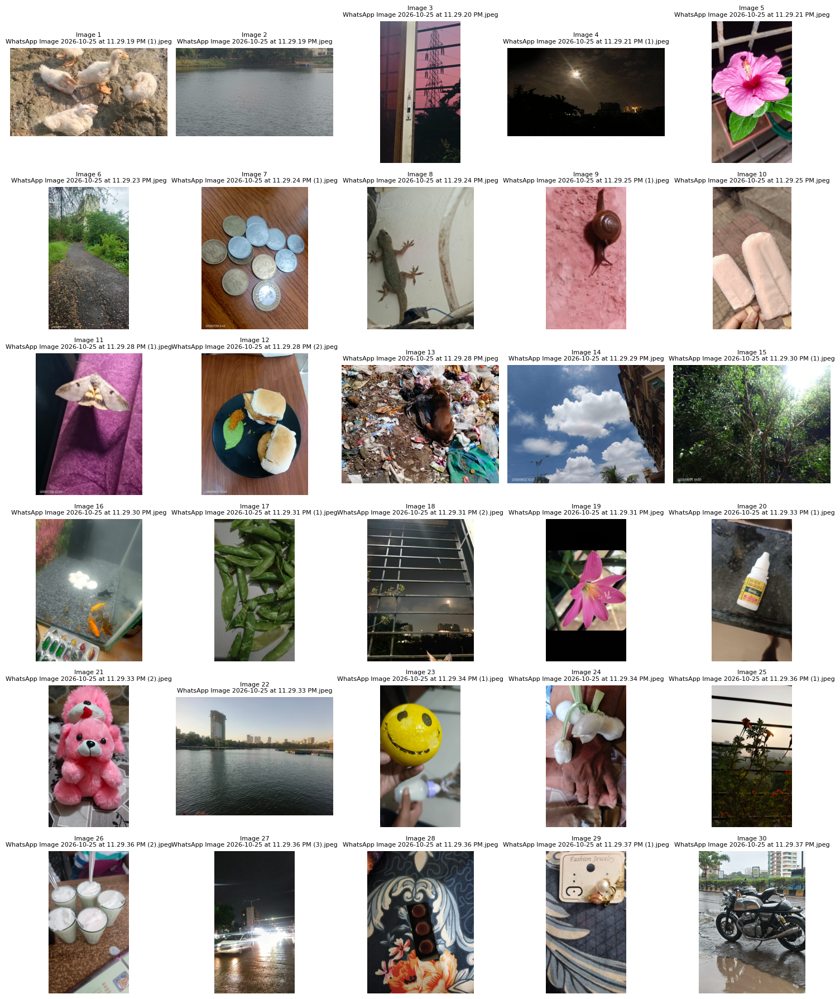

In [12]:

import zipfile
import os
from PIL import Image
from IPython.display import display
import matplotlib.pyplot as plt

# Extract the ZIP file
zip_path = next(iter(uploaded.keys()))
extract_folder = "/content/vision_images"

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_folder)

# Find and display all images
image_extensions = (".jpg", ".jpeg", ".png", ".webp")
image_paths = []

for root, dirs, filenames in os.walk(extract_folder):
    for filename in sorted(filenames):
        if filename.lower().endswith(image_extensions):
            image_paths.append(os.path.join(root, filename))

print("Total images found:", len(image_paths))

# Display thumbnails with filenames
cols = 5
rows = (len(image_paths) + cols - 1) // cols

plt.figure(figsize=(15, rows * 3))

for i, path in enumerate(image_paths):
    try:
        img = Image.open(path).convert("RGB")
        plt.subplot(rows, cols, i + 1)
        plt.imshow(img)
        plt.title(f"Image {i+1}\n{os.path.basename(path)}", fontsize=8)
        plt.axis("off")
    except Exception as e:
        print("Could not open:", path, e)

plt.tight_layout()
plt.show()


In [13]:

for i, path in enumerate(image_paths, start=1):
    print(f"{i}. {os.path.basename(path)}")


1. WhatsApp Image 2026-10-25 at 11.29.19 PM (1).jpeg
2. WhatsApp Image 2026-10-25 at 11.29.19 PM.jpeg
3. WhatsApp Image 2026-10-25 at 11.29.20 PM.jpeg
4. WhatsApp Image 2026-10-25 at 11.29.21 PM (1).jpeg
5. WhatsApp Image 2026-10-25 at 11.29.21 PM.jpeg
6. WhatsApp Image 2026-10-25 at 11.29.23 PM.jpeg
7. WhatsApp Image 2026-10-25 at 11.29.24 PM (1).jpeg
8. WhatsApp Image 2026-10-25 at 11.29.24 PM.jpeg
9. WhatsApp Image 2026-10-25 at 11.29.25 PM (1).jpeg
10. WhatsApp Image 2026-10-25 at 11.29.25 PM.jpeg
11. WhatsApp Image 2026-10-25 at 11.29.28 PM (1).jpeg
12. WhatsApp Image 2026-10-25 at 11.29.28 PM (2).jpeg
13. WhatsApp Image 2026-10-25 at 11.29.28 PM.jpeg
14. WhatsApp Image 2026-10-25 at 11.29.29 PM.jpeg
15. WhatsApp Image 2026-10-25 at 11.29.30 PM (1).jpeg
16. WhatsApp Image 2026-10-25 at 11.29.30 PM.jpeg
17. WhatsApp Image 2026-10-25 at 11.29.31 PM (1).jpeg
18. WhatsApp Image 2026-10-25 at 11.29.31 PM (2).jpeg
19. WhatsApp Image 2026-10-25 at 11.29.31 PM.jpeg
20. WhatsApp Image 2026

Image 1: WhatsApp Image 2026-10-25 at 11.29.19 PM (1).jpeg


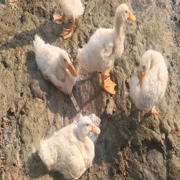

Image 2: WhatsApp Image 2026-10-25 at 11.29.19 PM.jpeg


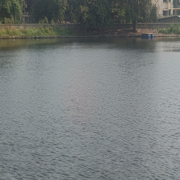

Image 3: WhatsApp Image 2026-10-25 at 11.29.20 PM.jpeg


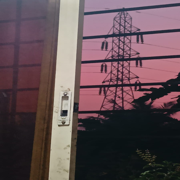

Image 4: WhatsApp Image 2026-10-25 at 11.29.21 PM (1).jpeg


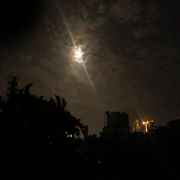

Image 5: WhatsApp Image 2026-10-25 at 11.29.21 PM.jpeg


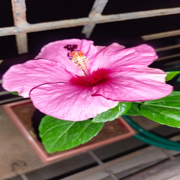

Image 6: WhatsApp Image 2026-10-25 at 11.29.23 PM.jpeg


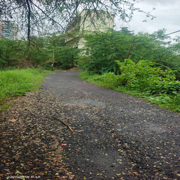

Image 7: WhatsApp Image 2026-10-25 at 11.29.24 PM (1).jpeg


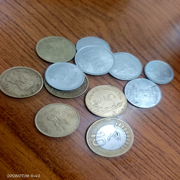

Image 8: WhatsApp Image 2026-10-25 at 11.29.24 PM.jpeg


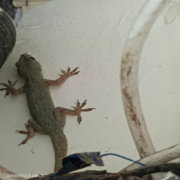

Image 9: WhatsApp Image 2026-10-25 at 11.29.25 PM (1).jpeg


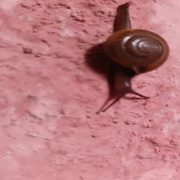

Image 10: WhatsApp Image 2026-10-25 at 11.29.25 PM.jpeg


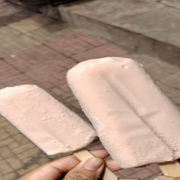

Image 11: WhatsApp Image 2026-10-25 at 11.29.28 PM (1).jpeg


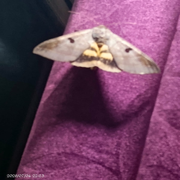

Image 12: WhatsApp Image 2026-10-25 at 11.29.28 PM (2).jpeg


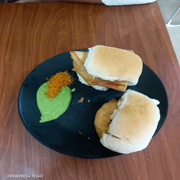

Image 13: WhatsApp Image 2026-10-25 at 11.29.28 PM.jpeg


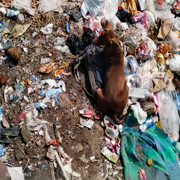

Image 14: WhatsApp Image 2026-10-25 at 11.29.29 PM.jpeg


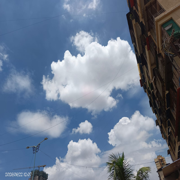

Image 15: WhatsApp Image 2026-10-25 at 11.29.30 PM (1).jpeg


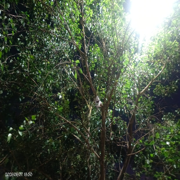

Image 16: WhatsApp Image 2026-10-25 at 11.29.30 PM.jpeg


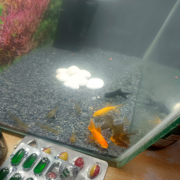

Image 17: WhatsApp Image 2026-10-25 at 11.29.31 PM (1).jpeg


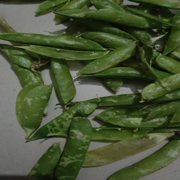

Image 18: WhatsApp Image 2026-10-25 at 11.29.31 PM (2).jpeg


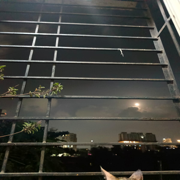

Image 19: WhatsApp Image 2026-10-25 at 11.29.31 PM.jpeg


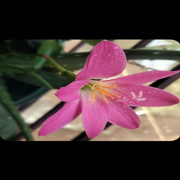

Image 20: WhatsApp Image 2026-10-25 at 11.29.33 PM (1).jpeg


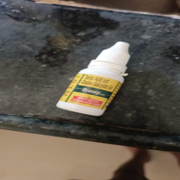

Image 21: WhatsApp Image 2026-10-25 at 11.29.33 PM (2).jpeg


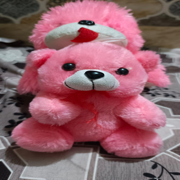

Image 22: WhatsApp Image 2026-10-25 at 11.29.33 PM.jpeg


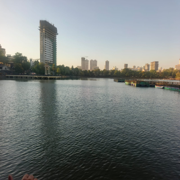

Image 23: WhatsApp Image 2026-10-25 at 11.29.34 PM (1).jpeg


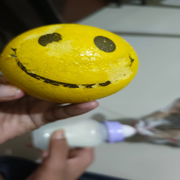

Image 24: WhatsApp Image 2026-10-25 at 11.29.34 PM.jpeg


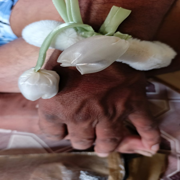

Image 25: WhatsApp Image 2026-10-25 at 11.29.36 PM (1).jpeg


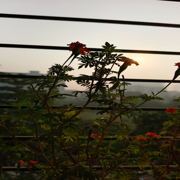

Image 26: WhatsApp Image 2026-10-25 at 11.29.36 PM (2).jpeg


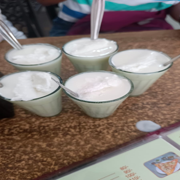

Image 27: WhatsApp Image 2026-10-25 at 11.29.36 PM (3).jpeg


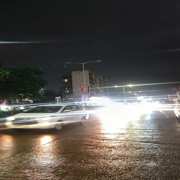

Image 28: WhatsApp Image 2026-10-25 at 11.29.36 PM.jpeg


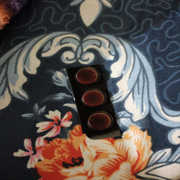

Image 29: WhatsApp Image 2026-10-25 at 11.29.37 PM (1).jpeg


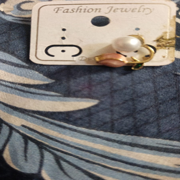

Image 30: WhatsApp Image 2026-10-25 at 11.29.37 PM.jpeg


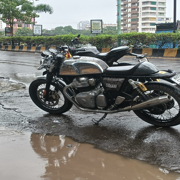

In [14]:

from IPython.display import display, Markdown

for i, path in enumerate(image_paths, start=1):
    img = Image.open(path).convert("RGB")
    print(f"Image {i}: {os.path.basename(path)}")
    display(img.resize((180, 180)))


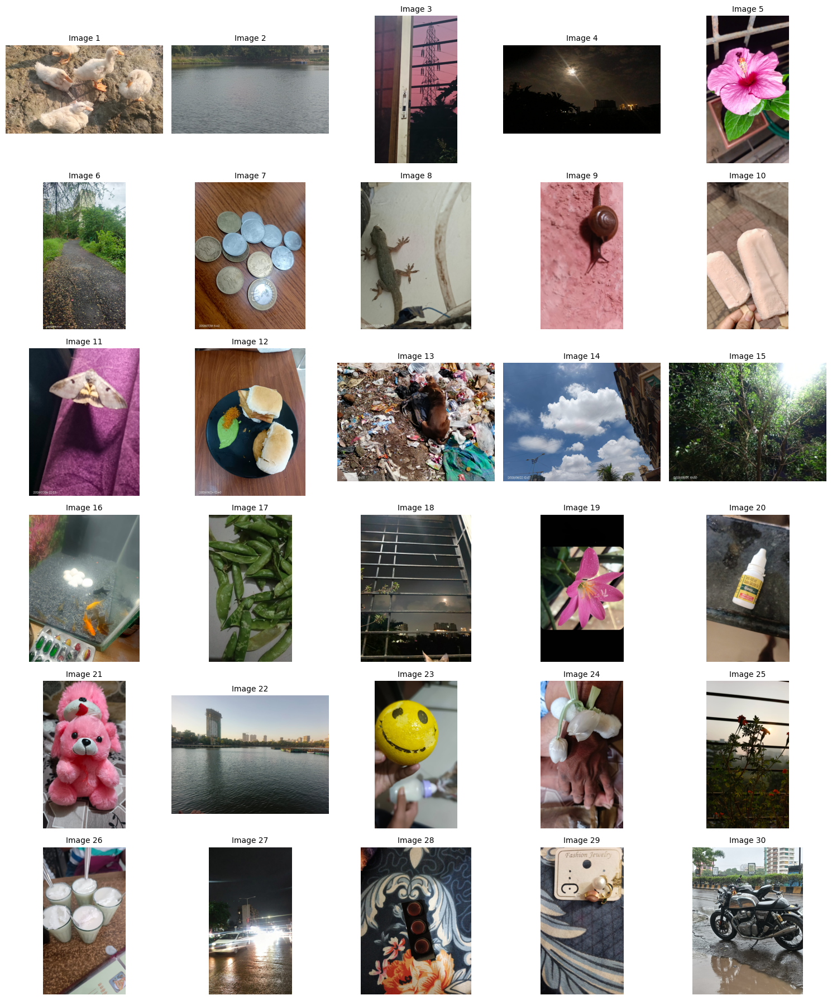

In [15]:

import matplotlib.pyplot as plt
from PIL import Image
import os
import math

cols = 5
rows = math.ceil(len(image_paths) / cols)

plt.figure(figsize=(15, rows * 3))

for i, path in enumerate(image_paths):
    img = Image.open(path).convert("RGB")

    plt.subplot(rows, cols, i + 1)
    plt.imshow(img)
    plt.title(f"Image {i+1}", fontsize=10)
    plt.axis("off")

plt.tight_layout()
plt.show()


In [16]:

for i, path in enumerate(image_paths, start=1):
    print(f"Image {i}: {os.path.basename(path)}")


Image 1: WhatsApp Image 2026-10-25 at 11.29.19 PM (1).jpeg
Image 2: WhatsApp Image 2026-10-25 at 11.29.19 PM.jpeg
Image 3: WhatsApp Image 2026-10-25 at 11.29.20 PM.jpeg
Image 4: WhatsApp Image 2026-10-25 at 11.29.21 PM (1).jpeg
Image 5: WhatsApp Image 2026-10-25 at 11.29.21 PM.jpeg
Image 6: WhatsApp Image 2026-10-25 at 11.29.23 PM.jpeg
Image 7: WhatsApp Image 2026-10-25 at 11.29.24 PM (1).jpeg
Image 8: WhatsApp Image 2026-10-25 at 11.29.24 PM.jpeg
Image 9: WhatsApp Image 2026-10-25 at 11.29.25 PM (1).jpeg
Image 10: WhatsApp Image 2026-10-25 at 11.29.25 PM.jpeg
Image 11: WhatsApp Image 2026-10-25 at 11.29.28 PM (1).jpeg
Image 12: WhatsApp Image 2026-10-25 at 11.29.28 PM (2).jpeg
Image 13: WhatsApp Image 2026-10-25 at 11.29.28 PM.jpeg
Image 14: WhatsApp Image 2026-10-25 at 11.29.29 PM.jpeg
Image 15: WhatsApp Image 2026-10-25 at 11.29.30 PM (1).jpeg
Image 16: WhatsApp Image 2026-10-25 at 11.29.30 PM.jpeg
Image 17: WhatsApp Image 2026-10-25 at 11.29.31 PM (1).jpeg
Image 18: WhatsApp Image 

In [21]:

ground_truth = {
    1: "ducks",
    2: "lake",
    3: "electricity wires and pole",
    4: "The moon",
    5: "hibiscus flower",
    6: "forest path",
    7: "coins",
    8: "lizard",
    9: "snail",
    10: "ice cream bars",
    11: "moth",
    12: "Fast Food",
    13: "A dog in a garbage area",
    14: "clouds",
    15: "tree",
    16: "fishes",
    17: "green pea pods",
    18: "building windows at night",
    19: "rain lily",
    20: "dropper bottle",
    21: "soft toys",
    22: "lake and city buildings",
    23: "yellow smiley ball",
    24: "Scrunchie",
    25: "flowering plant",
    26: "drink glasses",
    27: "night view",
    28: "medicine strip",
    29: "earring",
    30: "motorcycle"
}

for i, label in ground_truth.items():
    print(f"Image {i}: {label}")


Image 1: ducks
Image 2: lake
Image 3: electricity wires and pole
Image 4: The moon
Image 5: hibiscus flower
Image 6: forest path
Image 7: coins
Image 8: lizard
Image 9: snail
Image 10: ice cream bars
Image 11: moth
Image 12: Fast Food
Image 13: A dog in a garbage area
Image 14: clouds
Image 15: tree
Image 16: fishes
Image 17: green pea pods
Image 18: building windows at night
Image 19: rain lily
Image 20: dropper bottle
Image 21: soft toys
Image 22: lake and city buildings
Image 23: yellow smiley ball
Image 24: Scrunchie
Image 25: flowering plant
Image 26: drink glasses
Image 27: night view
Image 28: medicine strip
Image 29: earring
Image 30: motorcycle


In [22]:

from PIL import Image, ImageFilter
import torch
import pandas as pd
import os

# Fixed candidate labels for every image
candidate_categories = list(dict.fromkeys(ground_truth.values()))
candidate_prompts = [f"a photo of {label}" for label in candidate_categories]

blur_radii = [0, 5, 10, 15, 20, 25, 30]

all_scores = []
all_predictions = []

model.eval()

for image_number, path in enumerate(image_paths, start=1):
    original = Image.open(path).convert("RGB")
    true_label = ground_truth[image_number]

    for radius in blur_radii:
        if radius == 0:
            test_image = original
        else:
            test_image = original.filter(
                ImageFilter.GaussianBlur(radius=radius)
            )

        inputs = processor(
            text=candidate_prompts,
            images=test_image,
            return_tensors="pt",
            padding=True
        )

        with torch.no_grad():
            outputs = model(**inputs)
            scores = outputs.logits_per_image.softmax(dim=1)[0]

        top_index = scores.argmax().item()
        top_label = candidate_categories[top_index]
        true_index = candidate_categories.index(true_label)

        all_predictions.append({
            "image_number": image_number,
            "filename": os.path.basename(path),
            "ground_truth": true_label,
            "blur_radius": radius,
            "top_prediction": top_label,
            "top_prediction_score": scores[top_index].item(),
            "ground_truth_score": scores[true_index].item(),
            "prediction_correct": top_label == true_label
        })

        for category, prompt, score in zip(
            candidate_categories, candidate_prompts, scores
        ):
            all_scores.append({
                "image_number": image_number,
                "filename": os.path.basename(path),
                "ground_truth": true_label,
                "blur_radius": radius,
                "candidate_label": category,
                "candidate_prompt": prompt,
                "score": score.item()
            })

summary_df = pd.DataFrame(all_predictions)
scores_df = pd.DataFrame(all_scores)

summary_df.to_csv("summary_predictions.csv", index=False)
scores_df.to_csv("all_label_scores.csv", index=False)

print("Experiment complete!")
print("Images:", len(image_paths))
print("Blur levels:", len(blur_radii))
print("Predictions recorded:", len(summary_df))
print("Individual label scores recorded:", len(scores_df))

display(summary_df.head(10))


Experiment complete!
Images: 30
Blur levels: 7
Predictions recorded: 210
Individual label scores recorded: 6300


,image_number,filename,ground_truth,blur_radius,top_prediction,top_prediction_score,ground_truth_score,prediction_correct
0,1,WhatsApp Image 2026-10-25 at 11.29.19 PM (1).jpeg,ducks,0,ducks,0.989302,0.989302,True
1,1,WhatsApp Image 2026-10-25 at 11.29.19 PM (1).jpeg,ducks,5,ducks,0.984088,0.984088,True
2,1,WhatsApp Image 2026-10-25 at 11.29.19 PM (1).jpeg,ducks,10,ducks,0.977012,0.977012,True
3,1,WhatsApp Image 2026-10-25 at 11.29.19 PM (1).jpeg,ducks,15,ducks,0.850861,0.850861,True
4,1,WhatsApp Image 2026-10-25 at 11.29.19 PM (1).jpeg,ducks,20,fishes,0.117696,0.116773,False
5,1,WhatsApp Image 2026-10-25 at 11.29.19 PM (1).jpeg,ducks,25,ducks,0.101001,0.101001,True
6,1,WhatsApp Image 2026-10-25 at 11.29.19 PM (1).jpeg,ducks,30,fishes,0.088890,0.088254,False
7,2,WhatsApp Image 2026-10-25 at 11.29.19 PM.jpeg,lake,0,lake,0.869092,0.869092,True
8,2,WhatsApp Image 2026-10-25 at 11.29.19 PM.jpeg,lake,5,lake,0.923522,0.923522,True
9,2,WhatsApp Image 2026-10-25 at 11.29.19 PM.jpeg,lake,10,lake,0.930382,0.930382,True


Accuracy by blur level:


,accuracy_percent
blur_radius,
0,90.00
5,93.33
10,96.67
15,80.00
20,60.00
25,50.00
30,46.67


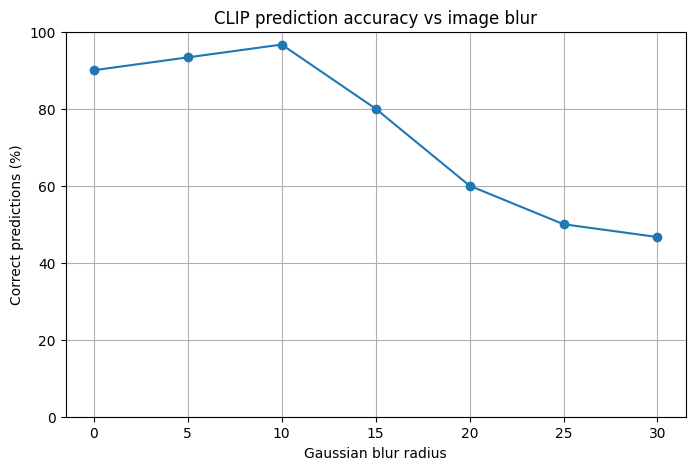

Mean score for the ground-truth label:


,mean_score_percent
blur_radius,
0,83.65
5,81.92
10,71.39
15,60.20
20,49.56
25,42.67
30,35.06


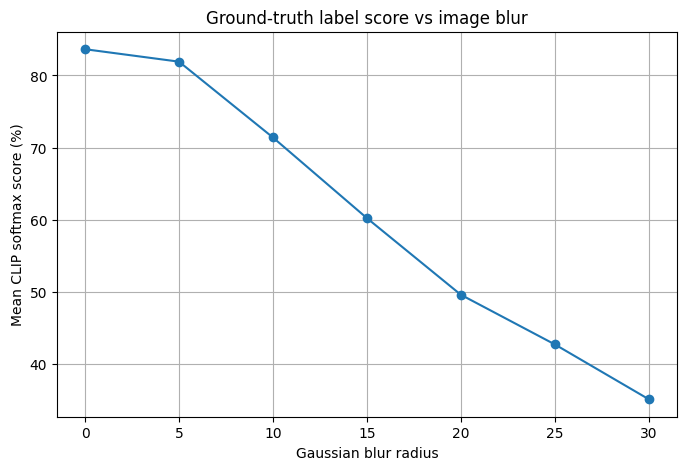

In [23]:

import matplotlib.pyplot as plt

# 1. Accuracy at each blur level
accuracy = summary_df.groupby("blur_radius")[
    "prediction_correct"
].mean() * 100

print("Accuracy by blur level:")
display(accuracy.rename("accuracy_percent").to_frame().round(2))

plt.figure(figsize=(8, 5))
plt.plot(accuracy.index, accuracy.values, marker="o")
plt.xlabel("Gaussian blur radius")
plt.ylabel("Correct predictions (%)")
plt.title("CLIP prediction accuracy vs image blur")
plt.xticks([0, 5, 10, 15, 20, 25, 30])
plt.ylim(0, 100)
plt.grid(True)
plt.show()

# 2. Average score assigned to the correct label
gt_scores = summary_df.groupby("blur_radius")[
    "ground_truth_score"
].mean() * 100

print("Mean score for the ground-truth label:")
display(gt_scores.rename("mean_score_percent").to_frame().round(2))

plt.figure(figsize=(8, 5))
plt.plot(gt_scores.index, gt_scores.values, marker="o")
plt.xlabel("Gaussian blur radius")
plt.ylabel("Mean CLIP softmax score (%)")
plt.title("Ground-truth label score vs image blur")
plt.xticks([0, 5, 10, 15, 20, 25, 30])
plt.grid(True)
plt.show()


In [24]:

# Compare predictions for each image before and after blur

comparison = summary_df.pivot(
    index=["image_number", "filename", "ground_truth"],
    columns="blur_radius",
    values="top_prediction"
).reset_index()

comparison = comparison.rename(columns={
    0: "prediction_original",
    30: "prediction_blur_30"
})

comparison["changed_at_radius_30"] = (
    comparison["prediction_original"]
    != comparison["prediction_blur_30"]
)

print("Images whose top prediction changed:")
display(
    comparison[comparison["changed_at_radius_30"]][
        ["image_number", "ground_truth",
         "prediction_original", "prediction_blur_30"]
    ]
)

print("Total changed:",
      comparison["changed_at_radius_30"].sum(),
      "out of", len(comparison))


Images whose top prediction changed:


blur_radius,image_number,ground_truth,prediction_original,prediction_blur_30
0,1,ducks,ducks,fishes
2,3,electricity wires and pole,electricity wires and pole,snail
4,5,hibiscus flower,hibiscus flower,flowering plant
9,10,ice cream bars,ice cream bars,coins
10,11,moth,moth,Scrunchie
15,16,fishes,fishes,medicine strip
16,17,green pea pods,green pea pods,flowering plant
17,18,building windows at night,building windows at night,motorcycle
18,19,rain lily,rain lily,Scrunchie
23,24,Scrunchie,hibiscus flower,soft toys


Total changed: 15 out of 30


In [31]:

from PIL import Image, ImageFilter
import pandas as pd
import torch

# Five images with incorrect original predictions
test_images = [15, 25, 26, 28, 29]
test_radii = [0, 15, 30]

diagnostic_categories = list(dict.fromkeys(ground_truth.values()))
diagnostic_prompts = [
    f"a photo of {category}" for category in diagnostic_categories
]

diagnostic_rows = []

for image_num in test_images:
    original = Image.open(image_paths[image_num - 1]).convert("RGB")

    for radius in test_radii:
        test_image = (
            original if radius == 0
            else original.filter(ImageFilter.GaussianBlur(radius=radius))
        )

        inputs = processor(
            text=diagnostic_prompts,
            images=test_image,
            return_tensors="pt",
            padding=True
        )

        with torch.no_grad():
            outputs = model(**inputs)
            scores = outputs.logits_per_image.softmax(dim=1)[0]

        top_idx = scores.argmax().item()

        diagnostic_rows.append({
            "image_number": image_num,
            "blur_radius": radius,
            "top_prediction": diagnostic_categories[top_idx],
            "top_score": scores[top_idx].item(),
            "ground_truth": ground_truth[image_num],
            "ground_truth_score": scores[
                diagnostic_categories.index(ground_truth[image_num])
            ].item(),
            "prediction_correct":
                diagnostic_categories[top_idx] == ground_truth[image_num]
        })

diagnostic_df = pd.DataFrame(diagnostic_rows)

display(diagnostic_df)
diagnostic_df.to_csv("five_image_diagnostic.csv", index=False)
print("Diagnostic complete! CSV saved.")


,image_number,blur_radius,top_prediction,top_score,ground_truth,ground_truth_score,prediction_correct
0,15,0,forest path,0.494963,tree,0.288115,False
1,15,15,tree,0.340748,tree,0.340748,True
2,15,30,forest path,0.219051,tree,0.182680,False
3,25,0,hibiscus flower,0.473146,flowering plant,0.471277,False
4,25,15,electricity wires and pole,0.356813,flowering plant,0.241075,False
5,25,30,medicine strip,0.085389,flowering plant,0.055253,False
6,26,0,drink glasses,0.735194,drink glasses,0.735194,True
7,26,15,drink glasses,0.450325,drink glasses,0.450325,True
8,26,30,coins,0.235005,drink glasses,0.051753,False
9,28,0,medicine strip,0.381301,medicine strip,0.381301,True


Diagnostic complete! CSV saved.


In [32]:
import torch
import pandas as pd
from PIL import Image, ImageFilter
from tqdm.auto import tqdm

# Correct the label for image 28
ground_truth[28] = "medicine tablets"

# Create a fixed candidate-label list from all 30 images
candidate_categories = list(dict.fromkeys(ground_truth.values()))
candidate_prompts = [
    f"a photo of {category}" for category in candidate_categories
]

blur_radii = [0, 5, 10, 15, 20, 25, 30]

device = next(model.parameters()).device

summary_rows = []
score_rows = []

for image_number, image_path in enumerate(
    tqdm(image_paths, desc="Testing images"), start=1
):
    original_image = Image.open(image_path).convert("RGB")
    true_label = ground_truth[image_number]

    for radius in blur_radii:
        if radius == 0:
            image = original_image
        else:
            image = original_image.filter(
                ImageFilter.GaussianBlur(radius=radius)
            )

        inputs = processor(
            text=candidate_prompts,
            images=image,
            return_tensors="pt",
            padding=True
        )
        inputs = {k: v.to(device) for k, v in inputs.items()}

        with torch.no_grad():
            outputs = model(**inputs)
            probabilities = outputs.logits_per_image.softmax(dim=1)[0]

        predicted_index = probabilities.argmax().item()
        top_prediction = candidate_categories[predicted_index]

        true_index = candidate_categories.index(true_label)
        true_score = probabilities[true_index].item()

        summary_rows.append({
            "image_number": image_number,
            "blur_radius": radius,
            "ground_truth": true_label,
            "top_prediction": top_prediction,
            "prediction_correct": top_prediction == true_label,
            "ground_truth_score": true_score
        })

        for category, score in zip(candidate_categories, probabilities.tolist()):
            score_rows.append({
                "image_number": image_number,
                "blur_radius": radius,
                "ground_truth": true_label,
                "candidate_label": category,
                "score": score
            })

summary_df = pd.DataFrame(summary_rows)
scores_df = pd.DataFrame(score_rows)

final_results = summary_df.groupby("blur_radius").agg(
    correct_predictions=("prediction_correct", "sum"),
    total_images=("prediction_correct", "count"),
    mean_ground_truth_score=("ground_truth_score", "mean")
).reset_index()

final_results["accuracy_percent"] = (
    final_results["correct_predictions"] /
    final_results["total_images"] * 100
)
final_results["error_rate_percent"] = 100 - final_results["accuracy_percent"]

summary_df.to_csv("summary_predictions_corrected.csv", index=False)
scores_df.to_csv("all_label_scores_corrected.csv", index=False)
final_results.to_csv("final_results_corrected.csv", index=False)

display(final_results.round(3))
print("Corrected experiment complete!")

Testing images:   0%|          | 0/30 [00:00<?, ?it/s]

,blur_radius,correct_predictions,total_images,mean_ground_truth_score,accuracy_percent,error_rate_percent
0,0,27,30,0.830,90.000,10.000
1,5,27,30,0.810,90.000,10.000
2,10,28,30,0.718,93.333,6.667
3,15,24,30,0.609,80.000,20.000
4,20,19,30,0.498,63.333,36.667
5,25,15,30,0.427,50.000,50.000
6,30,14,30,0.352,46.667,53.333


Corrected experiment complete!


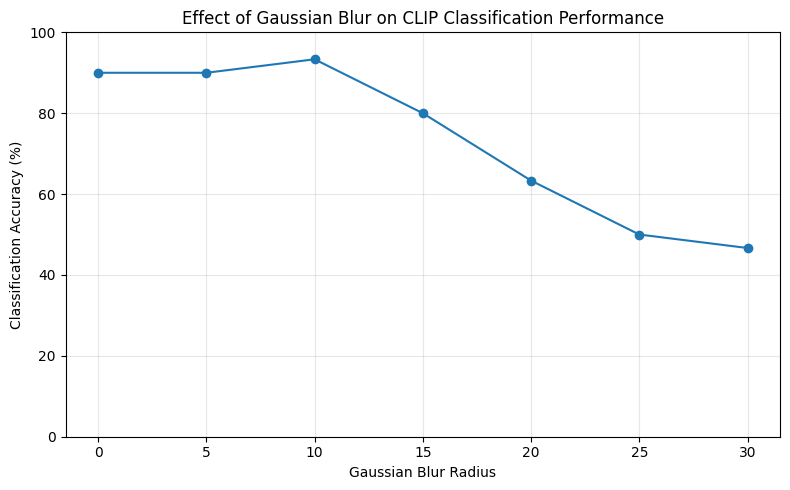

In [33]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(
    final_results["blur_radius"],
    final_results["accuracy_percent"],
    marker="o"
)

plt.xlabel("Gaussian Blur Radius")
plt.ylabel("Classification Accuracy (%)")
plt.title("Effect of Gaussian Blur on CLIP Classification Performance")
plt.xticks([0, 5, 10, 15, 20, 25, 30])
plt.ylim(0, 100)
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig("blur_performance.png", dpi=300)
plt.show()

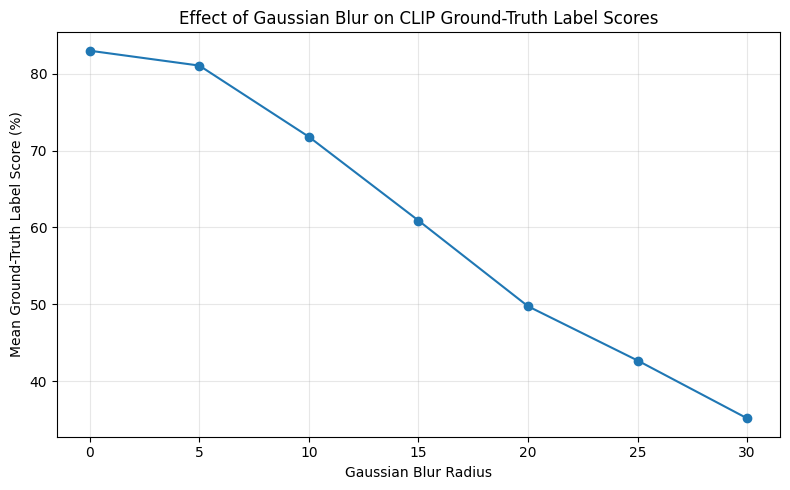

In [34]:
plt.figure(figsize=(8, 5))

plt.plot(
    final_results["blur_radius"],
    final_results["mean_ground_truth_score"] * 100,
    marker="o"
)

plt.xlabel("Gaussian Blur Radius")
plt.ylabel("Mean Ground-Truth Label Score (%)")
plt.title("Effect of Gaussian Blur on CLIP Ground-Truth Label Scores")
plt.xticks([0, 5, 10, 15, 20, 25, 30])
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig("ground_truth_score.png", dpi=300)
plt.show()

In [35]:
import zipfile
import os

zip_path = "/content/vision-images.zip"
extract_path = "/content/vision_images"

with zipfile.ZipFile(zip_path, "r") as z:
    z.extractall(extract_path)

print("Extracted files:")
print(os.listdir(extract_path)[:10])

Extracted files:
['WhatsApp Image 2026-10-25 at 11.29.33 PM (2).jpeg', 'WhatsApp Image 2026-10-25 at 11.29.25 PM.jpeg', 'WhatsApp Image 2026-10-25 at 11.29.30 PM.jpeg', 'WhatsApp Image 2026-10-25 at 11.29.30 PM (1).jpeg', 'WhatsApp Image 2026-10-25 at 11.29.21 PM.jpeg', 'WhatsApp Image 2026-10-25 at 11.29.21 PM (1).jpeg', 'WhatsApp Image 2026-10-25 at 11.29.37 PM (1).jpeg', 'WhatsApp Image 2026-10-25 at 11.29.19 PM.jpeg', 'WhatsApp Image 2026-10-25 at 11.29.20 PM.jpeg', 'WhatsApp Image 2026-10-25 at 11.29.29 PM.jpeg']


In [36]:
import os

folder = "/content/vision_images"

photos = [
    f for f in os.listdir(folder)
    if f.lower().endswith((".jpg", ".jpeg", ".png", ".webp"))
]

print("Total photos:", len(photos))
for i, name in enumerate(photos, 1):
    print(i, name)

Total photos: 30
1 WhatsApp Image 2026-10-25 at 11.29.33 PM (2).jpeg
2 WhatsApp Image 2026-10-25 at 11.29.25 PM.jpeg
3 WhatsApp Image 2026-10-25 at 11.29.30 PM.jpeg
4 WhatsApp Image 2026-10-25 at 11.29.30 PM (1).jpeg
5 WhatsApp Image 2026-10-25 at 11.29.21 PM.jpeg
6 WhatsApp Image 2026-10-25 at 11.29.21 PM (1).jpeg
7 WhatsApp Image 2026-10-25 at 11.29.37 PM (1).jpeg
8 WhatsApp Image 2026-10-25 at 11.29.19 PM.jpeg
9 WhatsApp Image 2026-10-25 at 11.29.20 PM.jpeg
10 WhatsApp Image 2026-10-25 at 11.29.29 PM.jpeg
11 WhatsApp Image 2026-10-25 at 11.29.34 PM.jpeg
12 WhatsApp Image 2026-10-25 at 11.29.25 PM (1).jpeg
13 WhatsApp Image 2026-10-25 at 11.29.28 PM.jpeg
14 WhatsApp Image 2026-10-25 at 11.29.37 PM.jpeg
15 WhatsApp Image 2026-10-25 at 11.29.33 PM.jpeg
16 WhatsApp Image 2026-10-25 at 11.29.31 PM (2).jpeg
17 WhatsApp Image 2026-10-25 at 11.29.24 PM (1).jpeg
18 WhatsApp Image 2026-10-25 at 11.29.36 PM (3).jpeg
19 WhatsApp Image 2026-10-25 at 11.29.33 PM (1).jpeg
20 WhatsApp Image 2026-10

In [38]:
from google.colab import files

uploaded = files.upload()

Saving pics.zip to pics.zip


In [39]:
import os, zipfile, torch, pandas as pd
from PIL import Image
from tqdm.auto import tqdm

# Extract uploaded ZIP
zip_path = next(iter(uploaded))
folder = "/content/form_test_images"
os.makedirs(folder, exist_ok=True)

with zipfile.ZipFile(zip_path, "r") as z:
    z.extractall(folder)

# Find all images
image_paths = sorted([
    os.path.join(root, f)
    for root, _, files_list in os.walk(folder)
    for f in files_list
    if f.lower().endswith((".jpg", ".jpeg", ".png", ".webp"))
])

print("Images found:", len(image_paths))
assert len(image_paths) == 24, "ZIP mein exactly 24 images honi chahiye."

# Use the same categories from your old notebook
categories = list(dict.fromkeys(ground_truth.values()))
prompts = [f"a photo of {c}" for c in categories]

device = next(model.parameters()).device
results = []

for path in tqdm(image_paths):
    img = Image.open(path).convert("RGB")

    inputs = processor(
        text=prompts, images=img,
        return_tensors="pt", padding=True
    )
    inputs = {k: v.to(device) for k, v in inputs.items()}

    with torch.no_grad():
        scores = model(**inputs).logits_per_image.softmax(dim=1)[0]

    idx = scores.argmax().item()

    results.append({
        "filename": os.path.basename(path),
        "top_prediction": categories[idx],
        "confidence_percent": round(scores[idx].item() * 100, 2)
    })

df = pd.DataFrame(results)
df.to_csv("/content/form_ai_results.csv", index=False)

display(df)
files.download("/content/form_ai_results.csv")

Images found: 24


  0%|          | 0/24 [00:00<?, ?it/s]

,filename,top_prediction,confidence_percent
0,01_normal.jpg,soft toys,98.73
1,02_normal.jpg,The moon,58.60
2,03_normal.jpg,ducks,98.92
3,04_normal.jpg,coins,99.93
4,05_normal.jpg,snail,99.86
5,06_normal.jpg,lizard,99.70
6,07_normal.jpg,hibiscus flower,51.29
7,08_normal.jpg,yellow smiley ball,100.00
8,09_medium_blur.jpg,earring,13.97
9,10_medium_blur.jpg,night view,15.90


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [40]:
for i, path in enumerate(image_paths, 1):
    print(i, os.path.basename(path))

1 01_normal.jpg
2 02_normal.jpg
3 03_normal.jpg
4 04_normal.jpg
5 05_normal.jpg
6 06_normal.jpg
7 07_normal.jpg
8 08_normal.jpg
9 09_medium_blur.jpg
10 10_medium_blur.jpg
11 11_medium_blur.jpg
12 12_medium_blur.jpg
13 13_medium_blur.jpg
14 14_medium_blur.jpg
15 15_medium_blur.jpg
16 16_medium_blur.jpg
17 17_heavy_blur.jpg
18 18_heavy_blur.jpg
19 19_heavy_blur.jpg
20 20_heavy_blur.jpg
21 21_heavy_blur.jpg
22 22_heavy_blur.jpg
23 23_heavy_blur.jpg
24 24_heavy_blur.jpg


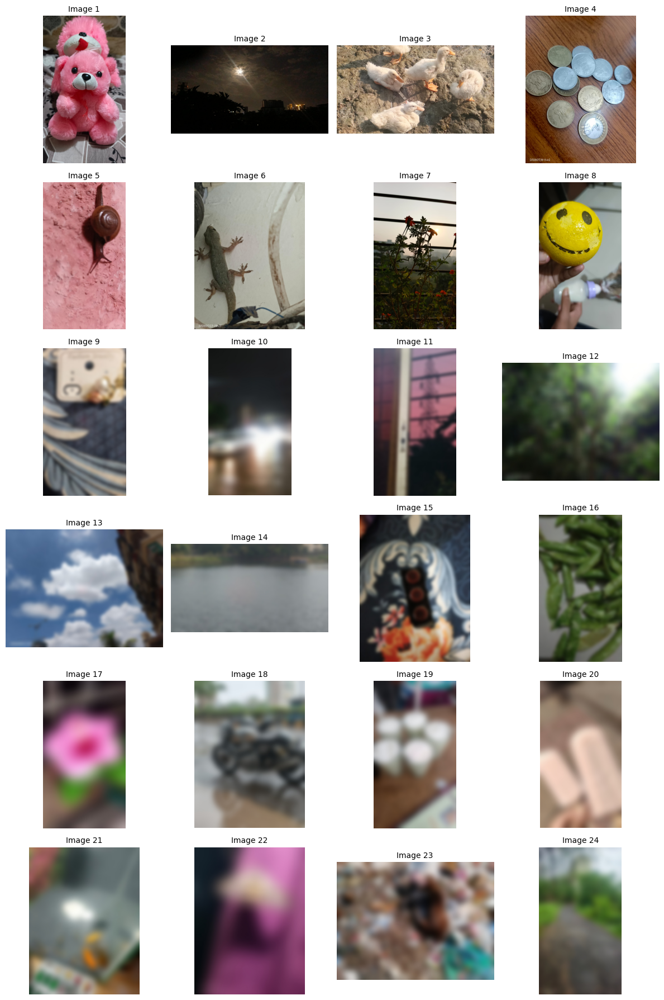

In [41]:
import matplotlib.pyplot as plt
from PIL import Image
import math

cols = 4
rows = math.ceil(len(image_paths) / cols)

fig, axes = plt.subplots(rows, cols, figsize=(12, 3 * rows))
axes = axes.flatten()

for i, path in enumerate(image_paths):
    img = Image.open(path).convert("RGB")
    axes[i].imshow(img)
    axes[i].set_title(f"Image {i+1}", fontsize=10)
    axes[i].axis("off")

for i in range(len(image_paths), len(axes)):
    axes[i].axis("off")

plt.tight_layout()
plt.show()

In [42]:
print("model:", "model" in globals())
print("processor:", "processor" in globals())
print("device:", "device" in globals())
print("image_paths:", "image_paths" in globals())
print("ground_truth:", "ground_truth" in globals())

model: True
processor: True
device: True
image_paths: True
ground_truth: True


In [43]:
!pip install -q transformers

In [44]:
import torch
import pandas as pd
from PIL import Image
from transformers import CLIPProcessor, CLIPModel
import os

device = "cuda" if torch.cuda.is_available() else "cpu"

model_name = "openai/clip-vit-base-patch32"

processor = CLIPProcessor.from_pretrained(model_name)
model = CLIPModel.from_pretrained(model_name).to(device)
model.eval()

print("CLIP model loaded successfully!")
print("Device:", device)

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

CLIP model loaded successfully!
Device: cpu


In [46]:
import zipfile
import os

zip_path = "/content/pics.zip"
folder = "/content/form_test_images"

os.makedirs(folder, exist_ok=True)

with zipfile.ZipFile(zip_path, "r") as z:
    z.extractall(folder)

image_paths = sorted([
    os.path.join(root, file)
    for root, dirs, files in os.walk(folder)
    for file in files
    if file.lower().endswith((".jpg", ".jpeg", ".png", ".webp"))
])

print("Images found:", len(image_paths))

Images found: 24


In [49]:
ground_truth = {
    1: "soft toys",
    2: "The moon",
    3: "ducks",
    4: "coins",
    5: "snail",
    6: "lizard",
    7: "flowering plant",
    8: "yellow smiley ball",
    9: "earring",
    10: "night view",
    11: "electricity wires and pole",
    12: "tree",
    13: "clouds",
    14: "lake and city buildings",
    15: "medicine strip",
    16: "green pea pods",
    17: "hibiscus flower",
    18: "motorcycle",
    19: "drink glasses",
    20: "ice cream bars",
    21: "fishes",
    22: "moth",
    23: "A dog in a garbage area",
    24: "road"
}

print("Ground-truth labels:", len(ground_truth))
print("Images loaded:", len(image_paths))


Ground-truth labels: 24
Images loaded: 24


In [50]:
results = []
labels = list(ground_truth.values())

for i, path in enumerate(image_paths, 1):
    image = Image.open(path).convert("RGB")

    inputs = processor(
        text=[f"a photo of {label}" for label in labels],
        images=image,
        return_tensors="pt",
        padding=True
    ).to(device)

    with torch.no_grad():
        outputs = model(**inputs)
        probs = outputs.logits_per_image.softmax(dim=1)[0]

    best = probs.argmax().item()

    results.append({
        "image": i,
        "ground_truth": ground_truth[i],
        "prediction": labels[best],
        "confidence_percent": round(probs[best].item() * 100, 2)
    })

df_form = pd.DataFrame(results)
display(df_form)
df_form.to_csv("/content/form_images_ai_results.csv", index=False)

print("Saved: form_images_ai_results.csv")

,image,ground_truth,prediction,confidence_percent
0,1,soft toys,soft toys,99.44
1,2,The moon,The moon,58.75
2,3,ducks,ducks,99.31
3,4,coins,coins,99.95
4,5,snail,snail,99.89
5,6,lizard,lizard,99.79
6,7,flowering plant,hibiscus flower,50.99
7,8,yellow smiley ball,yellow smiley ball,100.00
8,9,earring,earring,15.66
9,10,night view,night view,21.19


Saved: form_images_ai_results.csv


In [51]:
from google.colab import files

uploaded = files.upload()

Saving Human vs AI Image Recognition.csv (2).zip to Human vs AI Image Recognition.csv (2).zip


In [52]:
import pandas as pd

filename = next(iter(uploaded.keys()))
human_df = pd.read_csv(filename)

print("Total responses:", len(human_df))
print("\nColumn names:")
print(human_df.columns.tolist())

display(human_df.head())

Total responses: 5

Column names:
['Timestamp', 'What do you see in this image?', 'How confident are you in your answer?', 'What do you see in this image?.1', 'How confident are you in your answer?.1', 'What do you see in this image?.2', 'How confident are you in your answer?.2', 'What do you see in this image?.3', 'How confident are you in your answer?.3', 'What do you see in this image?.4', 'How confident are you in your answer?.4', 'What do you see in this image?.5', 'How confident are you in your answer?.5', 'What do you see in this image?.6', 'How confident are you in your answer?.6', 'What do you see in this image?.7', 'How confident are you in your answer?.7', 'What do you see in this image?.8', 'How confident are you in your answer?.8', 'What do you see in this image?.9', 'How confident are you in your answer?.9', 'What do you see in this image?.10', 'How confident are you in your answer?.10', 'What do you see in this image?.11', 'How confident are you in your answer?.11', 'Wha

,Timestamp,What do you see in this image?,How confident are you in your answer?,What do you see in this image?.1,How confident are you in your answer?.1,What do you see in this image?.2,How confident are you in your answer?.2,What do you see in this image?.3,How confident are you in your answer?.3,What do you see in this image?.4,...,What do you see in this image?.19,How confident are you in your answer?.19,What do you see in this image?.20,How confident are you in your answer?.20,What do you see in this image?.21,How confident are you in your answer?.21,What do you see in this image?.22,How confident are you in your answer?.22,What do you see in this image?.23,How confident are you in your answer?.23
0,2026/10/28 1:40:33 PM GMT+5:30,Teddy,5,Moon,5,Duck,5,Coins,5,Snail,...,Ice cream,5,Tatti,5,Flower,2,..,2,Road,3
1,2026/10/28 5:04:39 PM GMT+5:30,Soft toy,3,Air missile,3,Duck,3,Coins,4,Snail,...,Icecream,2,Colours,1,Don't know,1,Garbage,1,Gali,3
2,2026/10/28 8:55:23 PM GMT+5:30,soft toys,5,the moon,5,ducks,5,coins,5,snail,...,ice cream,4,colorful candies,2,insects,4,dog,1,the road,5
3,2026/10/28 10:24:19 PM GMT+5:30,Teddy bear,1,The night sky & the moon,1,Bird,1,Coins,1,A snail,...,Ice cream,1,Fish tank,5,Insect,5,Dog,1,Road,5
4,2026/10/28 10:32:30 PM GMT+5:30,Soft toys,1,Moon,1,Bird,1,Coins,1,Snail,...,Ice cream,1,Water tank,2,Moth,5,Garbage,2,Road,5


In [53]:
for i in range(24):
    print(i + 1, human_df.columns[1 + 2*i])

1 What do you see in this image?
2 What do you see in this image?.1
3 What do you see in this image?.2
4 What do you see in this image?.3
5 What do you see in this image?.4
6 What do you see in this image?.5
7 What do you see in this image?.6
8 What do you see in this image?.7
9 What do you see in this image?.8
10 What do you see in this image?.9
11 What do you see in this image?.10
12 What do you see in this image?.11
13 What do you see in this image?.12
14 What do you see in this image?.13
15 What do you see in this image?.14
16 What do you see in this image?.15
17 What do you see in this image?.16
18 What do you see in this image?.17
19 What do you see in this image?.18
20 What do you see in this image?.19
21 What do you see in this image?.20
22 What do you see in this image?.21
23 What do you see in this image?.22
24 What do you see in this image?.23


In [55]:
human_rows = []

for _, row in human_df.iterrows():
    for i in range(24):
        answer_col = human_df.columns[1 + 2*i]
        confidence_col = human_df.columns[2 + 2*i]

        human_rows.append({
            "image": i + 1,
            "answer": row[answer_col],
            "confidence": row[confidence_col]
        })

human_long = pd.DataFrame(human_rows)

print("Total human responses:", len(human_long))
display(human_long.head())

Total human responses: 120


,image,answer,confidence
0,1,Teddy,5
1,2,Moon,5
2,3,Duck,5
3,4,Coins,5
4,5,Snail,5


In [56]:
display(
    human_long[["image", "answer", "confidence"]]
    .groupby("image")
    .agg(list)
)

,answer,confidence
image,,
1,"[Teddy, Soft toy, soft toys, Teddy bear, Soft ...","[5, 3, 5, 1, 1]"
2,"[Moon, Air missile, the moon, The night sky & ...","[5, 3, 5, 1, 1]"
3,"[Duck, Duck, ducks, Bird, Bird]","[5, 3, 5, 1, 1]"
4,"[Coins , Coins, coins, Coins, Coins]","[5, 4, 5, 1, 1]"
5,"[Snail, Snail, snail, A snail, Snail]","[5, 3, 5, 1, 1]"
6,"[Lizard, Lizard, lizard, Lizard, Lizard]","[5, 3, 5, 1, 1]"
7,"[Flowers, Flowers , marigold, Flower, Flowers]","[5, 4, 5, 1, 1]"
8,"[Smily ball, Squishy ball, spunge ball, Ball &...","[5, 4, 5, 1, 1]"
9,"[It's blurry so can't see it, Earrings, earrin...","[3, 2, 5, 2, 2]"


In [58]:
from collections import Counter

human_summary = (
    human_long.groupby("image")
    .agg(
        most_common_answer=(
            "answer",
            lambda x: Counter(
                str(a).strip().lower() for a in x
            ).most_common(1)[0][0]
        ),
        average_confidence=("confidence", "mean"),
        participant_count=("answer", "count")
    )
    .reset_index()
)

human_summary["average_confidence"] = (
    human_summary["average_confidence"].round(2)
)

display(human_summary)

,image,most_common_answer,average_confidence,participant_count
0,1,soft toys,3.0,5
1,2,moon,3.0,5
2,3,duck,3.0,5
3,4,coins,3.2,5
4,5,snail,3.0,5
5,6,lizard,3.0,5
6,7,flowers,3.2,5
7,8,smily ball,3.2,5
8,9,earring,2.8,5
9,10,it's blurry,2.4,5


In [59]:
display(
    df_form[["image", "ground_truth", "prediction", "confidence_percent"]]
)

,image,ground_truth,prediction,confidence_percent
0,1,soft toys,soft toys,99.44
1,2,The moon,The moon,58.75
2,3,ducks,ducks,99.31
3,4,coins,coins,99.95
4,5,snail,snail,99.89
5,6,lizard,lizard,99.79
6,7,flowering plant,hibiscus flower,50.99
7,8,yellow smiley ball,yellow smiley ball,100.00
8,9,earring,earring,15.66
9,10,night view,night view,21.19


In [61]:
comparison_df = pd.merge(
    human_summary,
    df_form[
        ["image", "ground_truth", "prediction", "confidence_percent"]
    ],
    on="image",
    how="inner",
    validate="one_to_one"
)

comparison_df = comparison_df[
    [
        "image",
        "ground_truth",
        "most_common_answer",
        "prediction",
        "average_confidence",
        "confidence_percent",
        "participant_count"
    ]
]

print("Images compared:", len(comparison_df))
display(comparison_df)

Images compared: 24


,image,ground_truth,most_common_answer,prediction,average_confidence,confidence_percent,participant_count
0,1,soft toys,soft toys,soft toys,3.0,99.44,5
1,2,The moon,moon,The moon,3.0,58.75,5
2,3,ducks,duck,ducks,3.0,99.31,5
3,4,coins,coins,coins,3.2,99.95,5
4,5,snail,snail,snail,3.0,99.89,5
5,6,lizard,lizard,lizard,3.0,99.79,5
6,7,flowering plant,flowers,hibiscus flower,3.2,50.99,5
7,8,yellow smiley ball,smily ball,yellow smiley ball,3.2,100.00,5
8,9,earring,earring,earring,2.8,15.66,5
9,10,night view,it's blurry,night view,2.4,21.19,5


In [62]:
def normalize_label(label):
    label = str(label).strip().lower()

    equivalent_labels = {
    # Moon
    "moon": "the moon",
    "night sky and the moon": "the moon",
    "the night sky & the moon": "the moon",

    # Ducks
    "duck": "ducks",
    "birds": "ducks",
    "bird": "ducks",

    # Soft toys
    "soft toy": "soft toys",
    "teddy": "soft toys",
    "teddy bear": "soft toys",
    "teddy bears": "soft toys",
    "stuffed toys": "soft toys",
    "plush toys": "soft toys",

    # Flowers
    "flower": "flowering plant",
    "flowers": "flowering plant",
    "hibiscus": "hibiscus flower",

    # Smiley ball
    "smily ball": "yellow smiley ball",
    "smiley ball": "yellow smiley ball",
    "yellow ball": "yellow smiley ball",

    # Earring
    "earrings": "earring",

    # Electricity wires and pole
    "tower": "electricity wires and pole",
    "electric pole": "electricity wires and pole",
    "electricity pole": "electricity wires and pole",
    "power lines": "electricity wires and pole",
    "electric wires": "electricity wires and pole",

    # Tree and clouds
    "cloud": "clouds",

    # Lake
    "lake": "lake and city buildings",
    "water": "lake and city buildings",

    # Medicine strip
    "medicines": "medicine strip",
    "tablet strip": "medicine strip",
    "medicine tablets": "medicine strip",
    "pills": "medicine strip",

    # Pea pods
    "pea": "green pea pods",
    "peas": "green pea pods",
    "green peas": "green pea pods",
    "pea pods": "green pea pods",

    # Motorcycle
    "bike": "motorcycle",
    "motorbike": "motorcycle",

    # Drink glasses
    "drink": "drink glasses",
    "glasses": "drink glasses",
    "drinking glasses": "drink glasses",

    # Ice cream
    "icecream": "ice cream bars",
    "ice cream": "ice cream bars",

    # Fishes
    "fish": "fishes",

    # Dog in garbage area
    "dog": "a dog in a garbage area",
    "garbage": "a dog in a garbage area",
    "trash": "a dog in a garbage area",
    "dog and garbage": "a dog in a garbage area",
    "dog and pile of trash": "a dog in a garbage area",

    # Road
    "the road": "road",
    "street": "road",
    "gali": "road"
}

    return equivalent_labels.get(label, label)


comparison_df["human_correct"] = (
    comparison_df["most_common_answer"].apply(normalize_label)
    == comparison_df["ground_truth"].apply(normalize_label)
)

comparison_df["ai_correct"] = (
    comparison_df["prediction"].apply(normalize_label)
    == comparison_df["ground_truth"].apply(normalize_label)
)

human_accuracy = comparison_df["human_correct"].mean() * 100
ai_accuracy = comparison_df["ai_correct"].mean() * 100

print(f"Human accuracy: {human_accuracy:.2f}%")
print(f"AI accuracy: {ai_accuracy:.2f}%")
print("Images:", len(comparison_df))

Human accuracy: 83.33%
AI accuracy: 62.50%
Images: 24


In [63]:

import pandas as pd
import re

# Ground-truth labels for the 24 images
ground_truth_map = df_form.set_index("image")["ground_truth"].to_dict()

# Rebuild human responses while retaining participant numbers
evaluation_rows = []

for participant_index, (_, row) in enumerate(human_df.iterrows(), start=1):
    for i in range(24):
        answer_col = human_df.columns[1 + 2*i]
        confidence_col = human_df.columns[2 + 2*i]

        evaluation_rows.append({
            "participant": participant_index,
            "image": i + 1,
            "answer": row[answer_col],
            "confidence": row[confidence_col],
            "ground_truth": ground_truth_map[i + 1]
        })

human_evaluation = pd.DataFrame(evaluation_rows)

# Basic text normalisation only, no semantic substitutions
def clean_label(value):
    value = str(value).lower().strip()
    value = re.sub(r"[^\w\s]", "", value)
    value = re.sub(r"\s+", " ", value)
    return value

human_evaluation["answer_clean"] = human_evaluation["answer"].apply(clean_label)
human_evaluation["truth_clean"] = human_evaluation["ground_truth"].apply(clean_label)

human_evaluation["strict_correct"] = (
    human_evaluation["answer_clean"] == human_evaluation["truth_clean"]
)

# Individual participant accuracy
participant_accuracy = (
    human_evaluation.groupby("participant")["strict_correct"]
    .mean().mul(100).round(2)
    .reset_index(name="strict_accuracy_percent")
)

display(participant_accuracy)

print("Total responses:", len(human_evaluation))
print("Overall strict accuracy:",
      round(human_evaluation["strict_correct"].mean() * 100, 2), "%")


,participant,strict_accuracy_percent
0,1,16.67
1,2,12.50
2,3,29.17
3,4,16.67
4,5,33.33


Total responses: 120
Overall strict accuracy: 21.67 %


In [64]:

# Semantic label matching
# Only add equivalences that are justified by the image context.

semantic_aliases = {
    "moon": "the moon",
    "night sky and the moon": "the moon",
    "the night sky and the moon": "the moon",

    "duck": "ducks",

    "soft toy": "soft toys",
    "teddy": "soft toys",
    "teddy bear": "soft toys",
    "teddy bears": "soft toys",
    "stuffed toys": "soft toys",
    "plush toys": "soft toys",

    "smily ball": "yellow smiley ball",
    "smiley ball": "yellow smiley ball",

    "earrings": "earring",
    "cloud": "clouds",

    "bike": "motorcycle",
    "motorbike": "motorcycle",

    "drinking glasses": "drink glasses",
    "icecream": "ice cream bars",

    "fish": "fishes",

    "the road": "road",
    "street": "road",
    "gali": "road"
}

def semantic_normalize(value):
    label = clean_label(value)
    return semantic_aliases.get(label, label)

human_evaluation["semantic_answer"] = (
    human_evaluation["answer"].apply(semantic_normalize)
)

human_evaluation["semantic_truth"] = (
    human_evaluation["ground_truth"].apply(semantic_normalize)
)

human_evaluation["semantic_correct"] = (
    human_evaluation["semantic_answer"] ==
    human_evaluation["semantic_truth"]
)

# Accuracy for each participant
semantic_participant_accuracy = (
    human_evaluation.groupby("participant")["semantic_correct"]
    .mean().mul(100).round(2)
    .reset_index(name="semantic_accuracy_percent")
)

display(semantic_participant_accuracy)

# Overall semantic accuracy
overall_semantic_accuracy = round(
    human_evaluation["semantic_correct"].mean() * 100, 2
)

print("Total responses:", len(human_evaluation))
print("Overall semantic human accuracy:",
      overall_semantic_accuracy, "%")


,participant,semantic_accuracy_percent
0,1,37.50
1,2,37.50
2,3,41.67
3,4,29.17
4,5,45.83


Total responses: 120
Overall semantic human accuracy: 38.33 %


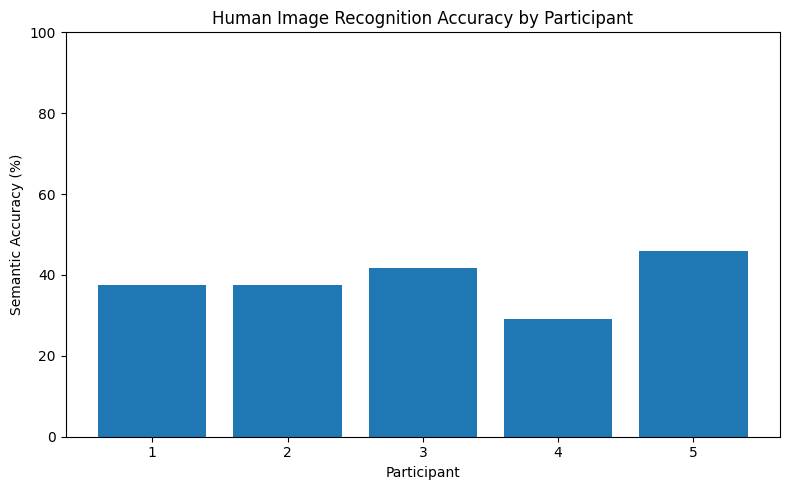

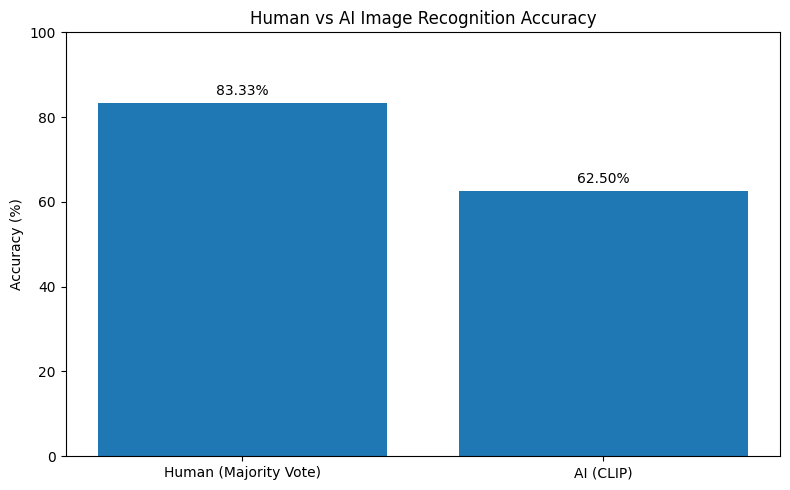

In [68]:
import matplotlib.pyplot as plt

# CHART 1: Human vs AI accuracy
methods = ["Human (Majority Vote)", "AI (CLIP)"]
accuracies = [83.33, 62.50]

plt.figure(figsize=(8, 5))
bars = plt.bar(methods, accuracies)

plt.title("Human vs AI Image Recognition Accuracy")
plt.ylabel("Accuracy (%)")
plt.ylim(0, 100)

for bar, value in zip(bars, accuracies):
    plt.text(
        bar.get_x() + bar.get_width()/2,
        value + 2,
        f"{value:.2f}%",
        ha="center"
    )

plt.tight_layout()
plt.savefig("human_vs_ai_accuracy.png", dpi=300)
plt.show()


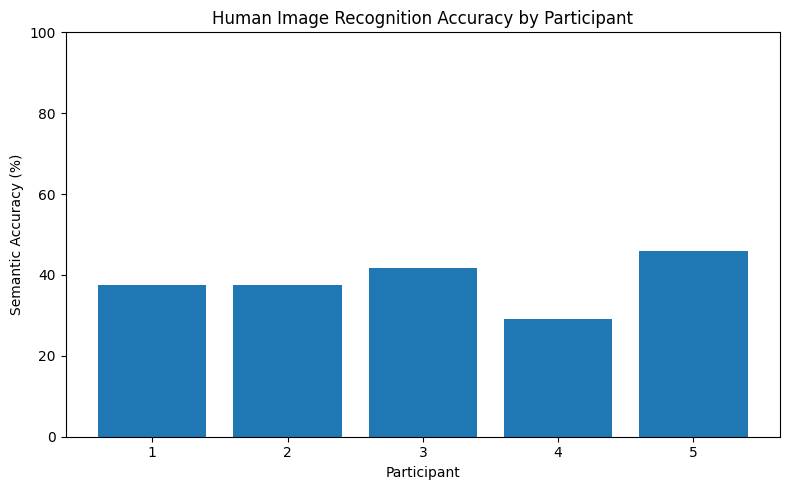

In [69]:

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.bar(
    semantic_participant_accuracy["participant"].astype(str),
    semantic_participant_accuracy["semantic_accuracy_percent"]
)

plt.xlabel("Participant")
plt.ylabel("Semantic Accuracy (%)")
plt.title("Human Image Recognition Accuracy by Participant")
plt.ylim(0, 100)

plt.tight_layout()
plt.show()



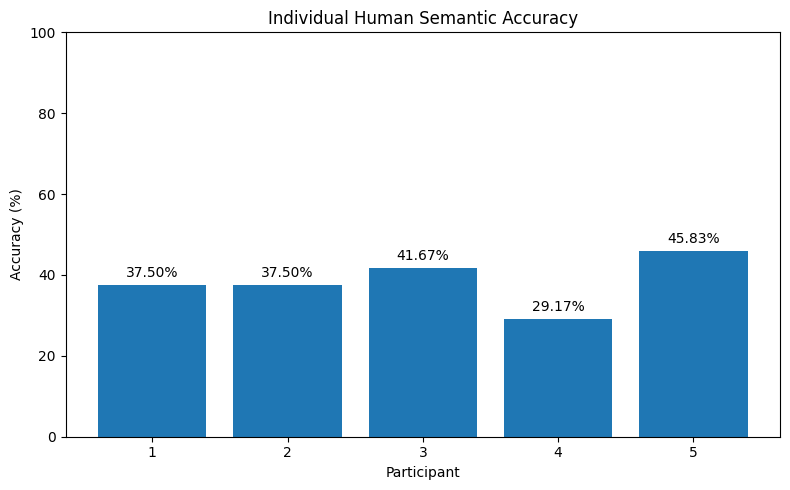

In [67]:
# CHART 2: Individual human semantic accuracy
participants = semantic_participant_accuracy["participant"].astype(str)
scores = semantic_participant_accuracy["semantic_accuracy_percent"]

plt.figure(figsize=(8, 5))
bars = plt.bar(participants, scores)

plt.title("Individual Human Semantic Accuracy")
plt.xlabel("Participant")
plt.ylabel("Accuracy (%)")
plt.ylim(0, 100)

for bar, value in zip(bars, scores):
    plt.text(
        bar.get_x() + bar.get_width()/2,
        value + 2,
        f"{value:.2f}%",
        ha="center"
    )

plt.tight_layout()
plt.savefig("individual_human_accuracy.png", dpi=300)
plt.show()
